# Polity maps
Active individuals per Cliopatria polity (polities of the active life) at four century snapshots.

In [1]:
import json
import random
import tempfile

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import shape
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
BASEMAP_PATH = '../../data/ne_110m_admin_0_countries.geojson'

pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)

CENTURY_SNAPSHOTS = [-400, 500, 1400, 1900]

apply_style()

## External data — Natural Earth basemap

In [2]:
basemap = gpd.read_file(BASEMAP_PATH)
print('basemap countries:', len(basemap))

basemap countries: 177


## Load data
### Active-life polity matches

In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET threads=4; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql("""
    CREATE TEMP TABLE matches AS
    SELECT entity.qid                AS qid,
           match.cliopatria_id       AS polity_id,
           match.name                AS polity_name,
           start_of_active_life.year AS active_start,
           end_of_active_life.year   AS active_end
    FROM   individual_enriched,
           unnest(list_transform(active_life_polity, stage_match -> {'cliopatria_id': stage_match.polity.cliopatria_id,
                                                                   'name': stage_match.polity.name})) AS unnested(match)
""")
match_stats = con.sql('SELECT COUNT(*) AS matches, COUNT(DISTINCT qid) AS individuals, COUNT(*) - COUNT(active_start) AS missing_active_life FROM matches').pl()
assert match_stats['missing_active_life'][0] == 0
match_stats

matches,individuals,missing_active_life
i64,i64,i64
3724173,3546784,0


### Active individuals per polity and century

In [4]:
con.sql("CREATE TEMP TABLE centuries AS SELECT unnest($centuries) AS century",
        params={'centuries': sorted(CENTURY_SNAPSHOTS)})

century_counts = con.sql("""
    SELECT   centuries.century                              AS century,
             matches.polity_id                            AS polity_id,
             matches.polity_name                          AS polity_name,
             COUNT(DISTINCT matches.qid)                  AS n_all
    FROM     matches
    JOIN     centuries ON matches.active_start <= centuries.century + 99 AND matches.active_end >= centuries.century
    GROUP BY centuries.century, matches.polity_id, matches.polity_name
""").pl()

assert century_counts.select('century', 'polity_id').is_duplicated().sum() == 0
print('shape:', century_counts.shape)
century_counts.sort('n_all', descending=True).head()

shape: (659, 4)


century,polity_id,polity_name,n_all
i32,i64,str,i64
1900,1148,"""United States of America""",365086
1900,1389,"""Union of Soviet Socialist Republics""",199992
1900,1102,"""Kingdom of Great Britain""",151623
1900,1467,"""French Fifth Republic""",87985
1900,1375,"""Czechoslovakia""",87327


### Polygon per polity and century

In [5]:
con.sql("""
    CREATE TEMP TABLE territories AS
    SELECT cliopatria_id        AS polity_id,
           name                 AS polity_name,
           territory.start_year AS start_year,
           territory.end_year   AS end_year,
           territory.geometry   AS geometry
    FROM   polity, unnest(territories) AS unnested(territory)
""")

polygons = con.sql("""
    SELECT  centuries.century, territories.polity_id, territories.polity_name, territories.start_year, territories.end_year, territories.geometry
    FROM    territories
    JOIN    centuries ON territories.start_year <= centuries.century + 99 AND territories.end_year >= centuries.century
    QUALIFY row_number() OVER (
                PARTITION BY centuries.century, territories.polity_id
                ORDER BY abs((territories.start_year + territories.end_year) / 2.0 - (centuries.century + 50)), territories.start_year
            ) = 1
""").pl()

con.close()

assert polygons.select('century', 'polity_id').is_duplicated().sum() == 0
print('shape:', polygons.shape)
print(polygons.group_by('century').len().sort('century'))
polygons.drop('geometry').head()

shape: (760, 6)
shape: (4, 2)
┌─────────┬─────┐
│ century ┆ len │
│ ---     ┆ --- │
│ i32     ┆ u32 │
╞═════════╪═════╡
│ -400    ┆ 58  │
│ 500     ┆ 112 │
│ 1400    ┆ 240 │
│ 1900    ┆ 350 │
└─────────┴─────┘


century,polity_id,polity_name,start_year,end_year
i32,i64,str,i64,i64
-400,32,"""Kingdom of Kush""",-630,337
-400,52,"""Wey""",-366,-351
-400,92,"""Yue""",-337,-334
-400,97,"""Odrysian Kingdom""",-350,-338
500,251,"""Baekje""",476,566


## Preprocessing

In [6]:
def century_frame(century, count_column):
    """Polities active in the century, with count and representative geometry."""
    counts = century_counts.filter((pl.col('century') == century) & (pl.col(count_column) > 0))
    joined = counts.join(polygons.filter(pl.col('century') == century).select('polity_id', 'geometry'),
                         on='polity_id', how='inner')
    return gpd.GeoDataFrame({'name': joined['polity_name'].to_list(),
                             'count': joined[count_column].to_list()},
                            geometry=[shape(json.loads(g)).buffer(0) for g in joined['geometry']], crs='EPSG:4326')


def century_label(century):
    return f'{abs(century)} BCE' if century < 0 else f'{century} CE'


def add_log_colorbar(fig, norm, label):
    cbar_ax = fig.add_axes([0.30, 0.05, 0.42, 0.016])
    mappable = ScalarMappable(norm=norm, cmap=MAP_COLORMAP)
    cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
    ticks = list(range(int(np.floor(norm.vmax)) + 1))
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f'{10 ** t:,}' for t in ticks])
    cbar.set_label(label)


def render_century_maps(frames, colorbar_label):
    norm = Normalize(vmin=0, vmax=max(np.log10(f['count'].max() + 1) for f in frames.values()))
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
    for ax, (century, frame) in zip(axes.flatten(), frames.items()):
        basemap.boundary.plot(ax=ax, color=BASEMAP_COLOR, linewidth=0.5, zorder=1)
        frame.assign(log_count=np.log10(frame['count'] + 1)).plot(
            ax=ax, column='log_count', cmap=MAP_COLORMAP, norm=norm, edgecolor=BACKGROUND_COLOR, linewidth=0.25, zorder=2)
        ax.set_xlim(-180, 180); ax.set_ylim(-60, 85)
        ax.set_axis_off()
        ax.text(0.02, 0.97, century_label(century), transform=ax.transAxes, fontsize=MAP_PANEL_LABEL_FONTSIZE, va='top')
    fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.10, wspace=0.02, hspace=0.05)
    add_log_colorbar(fig, norm, colorbar_label)
    plt.show()

## Figures
### Figure 5: Active individuals per polity in 400 BCE, 500, 1400 and 1900 CE

#### Data plotted

In [7]:
century_frames = {c: century_frame(c, 'n_all') for c in CENTURY_SNAPSHOTS}
century_map_data = pl.concat([
    pl.DataFrame({'century': century, 'name': frame['name'].to_list(), 'count': frame['count'].to_list(),
                  'geometry': frame.geometry.to_wkt().to_list()})
    for century, frame in century_frames.items()
])
print('shape:', century_map_data.shape)
century_map_data

shape: (606, 4)


century,name,count,geometry
i32,str,i64,str
-400,"""Wey""",2,"""POLYGON ((114.58152 36.030804, 114.609795 36.095196, 115.441…"
-400,"""Odrysian Kingdom""",3,"""MULTIPOLYGON (((27.924486 41.911442, 28.004253 41.911442, 28…"
-400,"""Qin""",10,"""POLYGON ((111.082497 35.451431, 111.055893 35.38707, 110.588…"
-400,"""Macedonian Empire""",87,"""POLYGON ((22.89249 40.61441, 22.813276 40.61441, 22.571581 4…"
-400,"""Thirtieth Dynasty of Egypt""",6,"""POLYGON ((23.903419 32.043148, 23.97975 32.043148, 24.892485…"
-400,"""Ptolemaic Kingdom""",5,"""POLYGON ((34.372715 41.197685, 34.364449 41.132843, 34.26861…"
-400,"""Greek City-States""",62,"""MULTIPOLYGON (((40.415703 43.146725, 40.219173 43.407204, 39…"
-400,"""Cimmerian Bosporus""",7,"""MULTIPOLYGON (((36.748737 45.431332, 37.216339 45.300438, 37…"
-400,"""Han""",3,"""POLYGON ((112.938637 35.451431, 112.319923 35.451431, 112.26…"


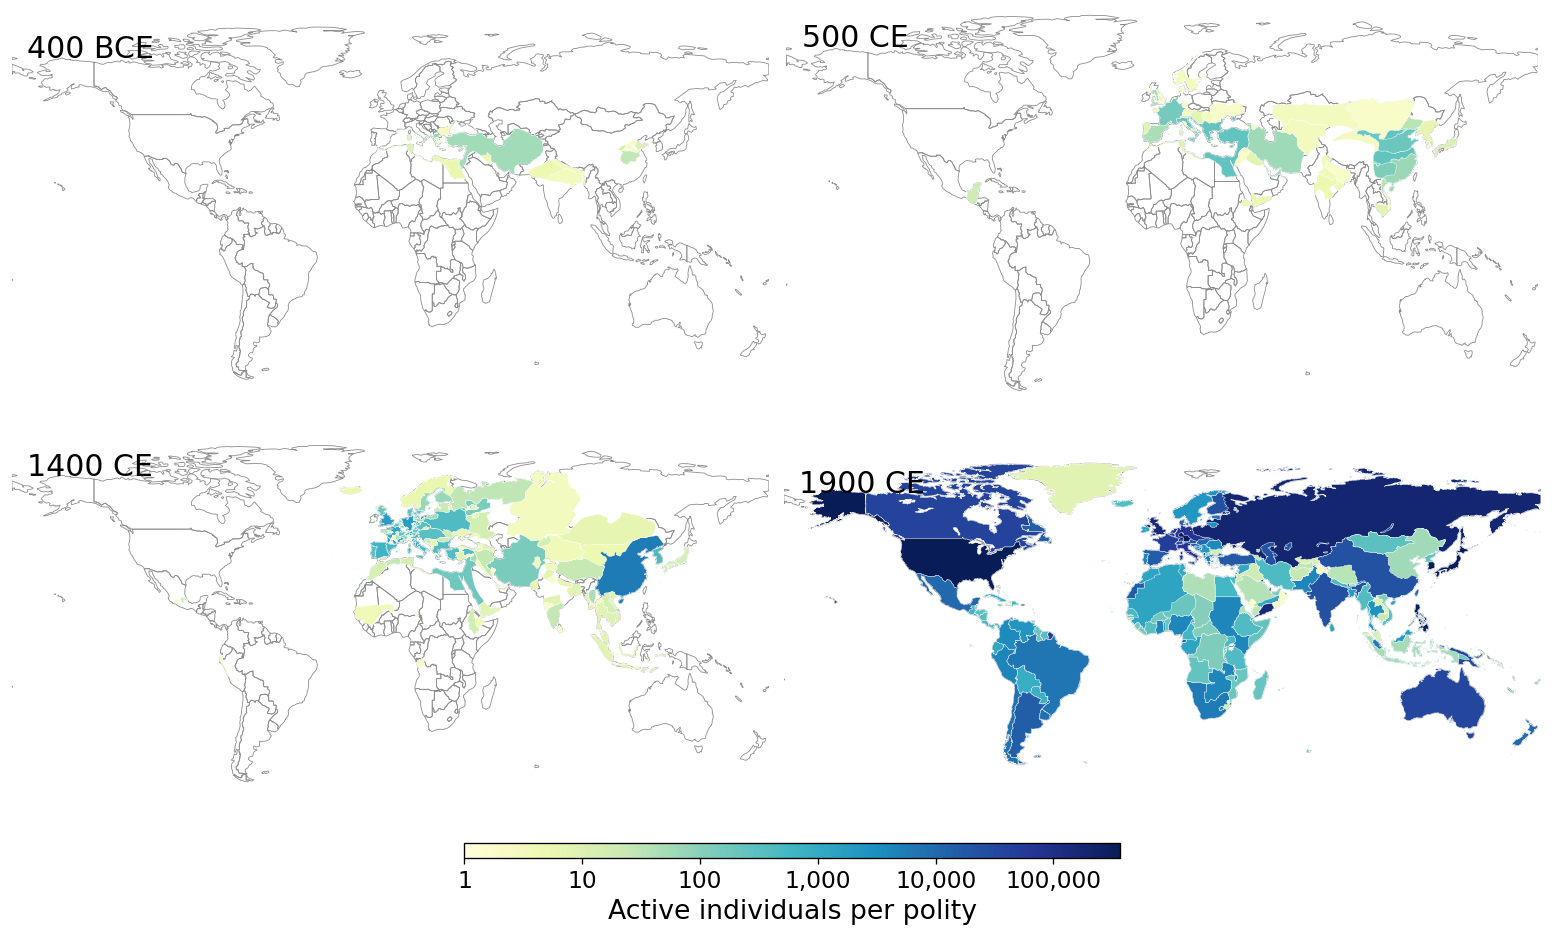

In [8]:
render_century_maps(century_frames, 'Active individuals per polity')